In [1]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [4]:
train.isnull().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [5]:
for col in ["Gender", "Customer Type", "Type of Travel", "Class"]:
    print("\n", col)
    print(train[col].value_counts())


 Gender
Gender
Male      351683
Female    347952
Name: count, dtype: int64

 Customer Type
Customer Type
Loyal Customer       576990
disloyal Customer    122645
Name: count, dtype: int64

 Type of Travel
Type of Travel
Business travel    497441
Personal Travel    202194
Name: count, dtype: int64

 Class
Class
Business    342212
Eco         327404
Eco Plus     30019
Name: count, dtype: int64


In [6]:
train["satisfaction"].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

In [7]:
train["satisfaction"].value_counts(normalize=True)

satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64

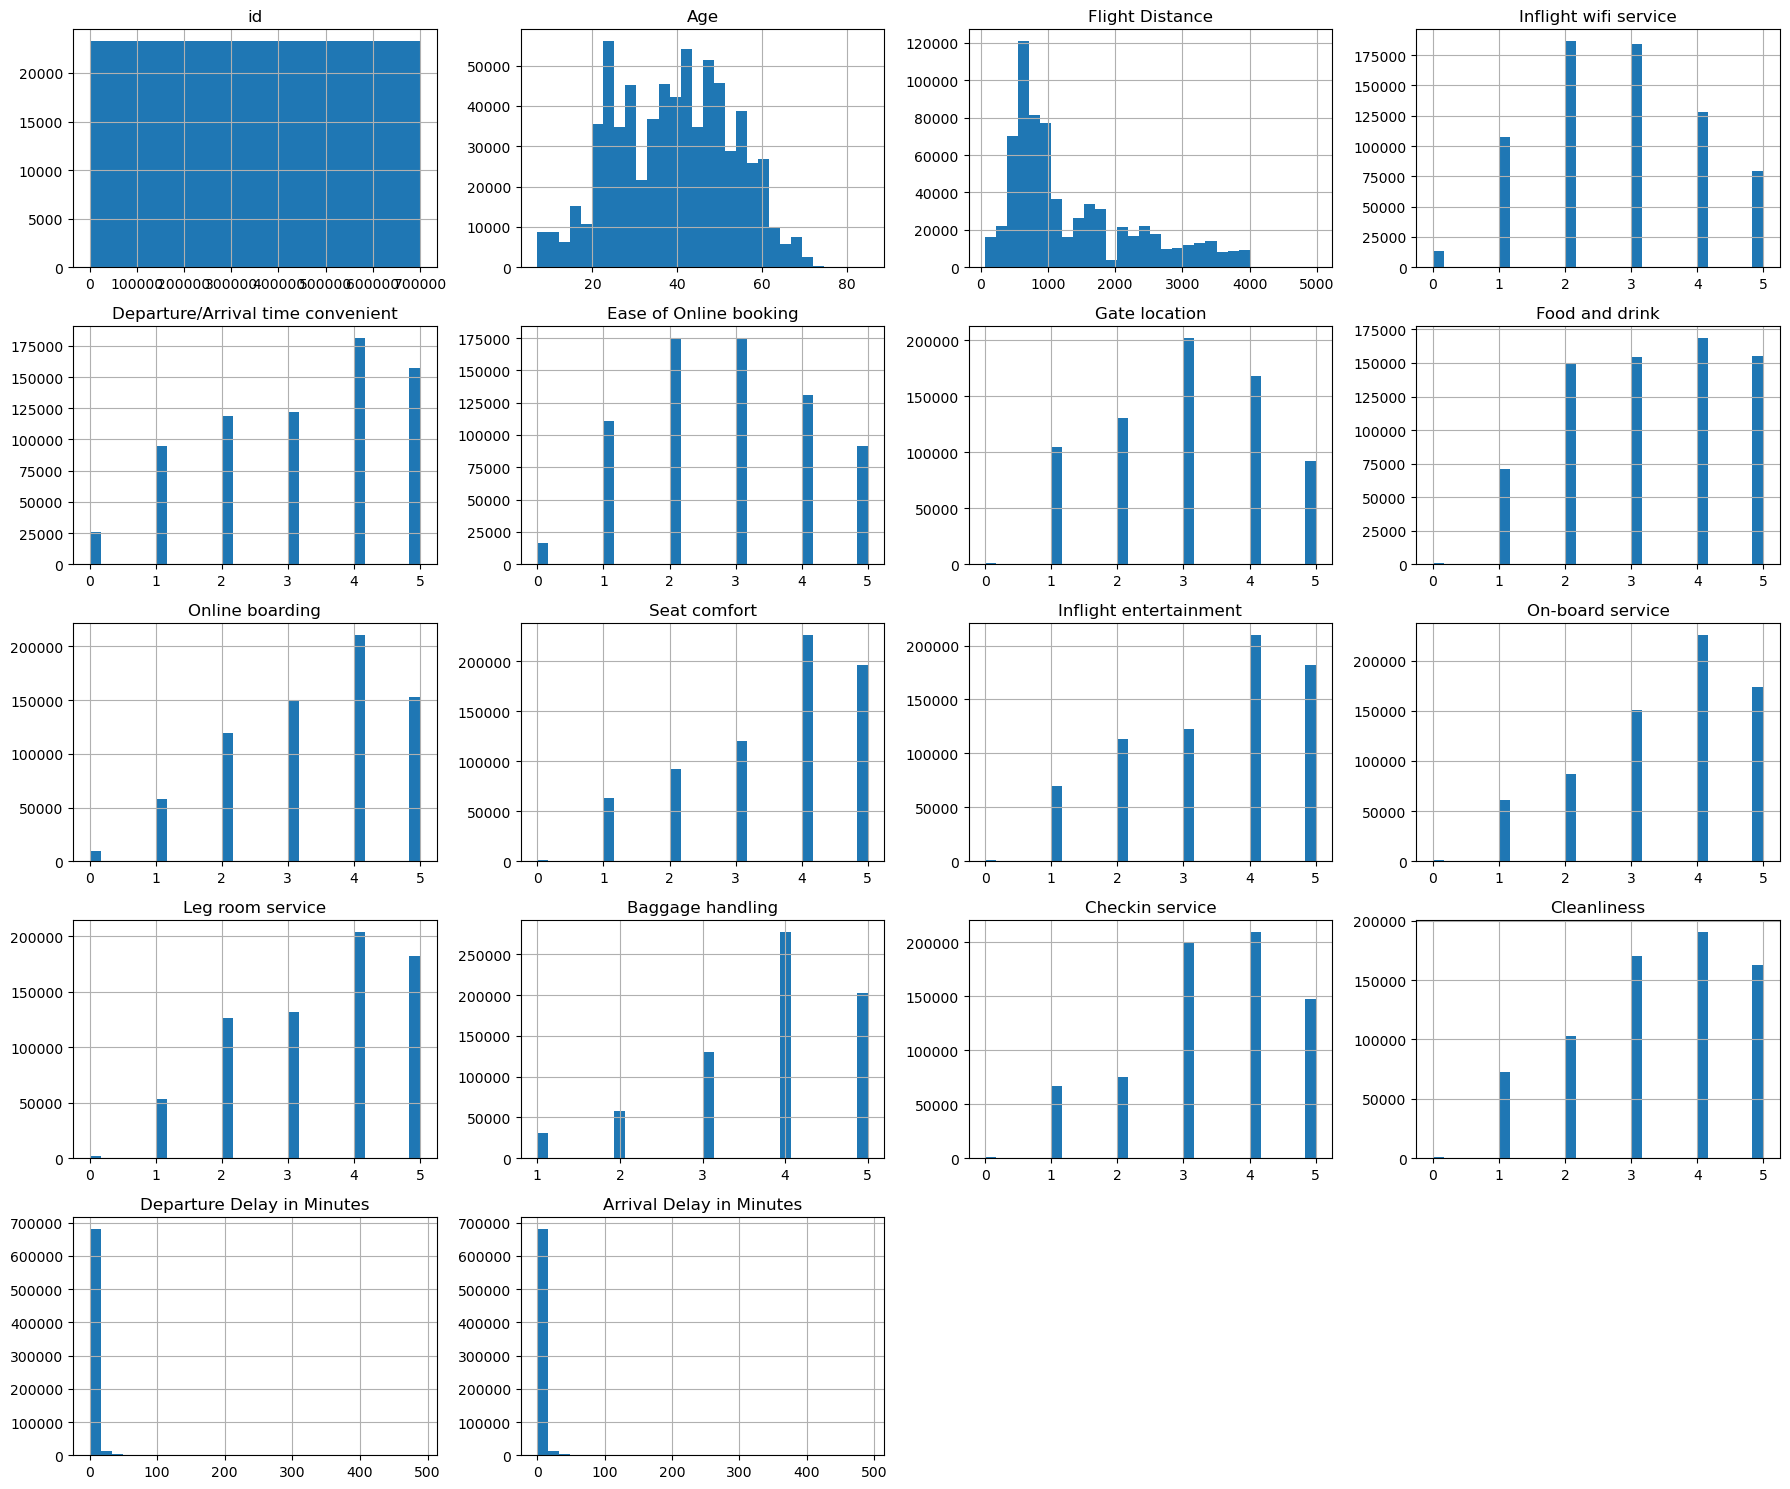

In [8]:
train.hist(figsize=(18, 15), bins=30)
plt.tight_layout()
plt.show()

In [9]:
comparison = train.groupby("satisfaction").mean(numeric_only=True).T

comparison

satisfaction,False,True
id,349794.488990,349845.238301
Age,36.504131,42.135220
Flight Distance,1038.448556,1749.335704
Inflight wifi service,2.445730,3.196434
Departure/Arrival time convenient,3.221002,3.074934
Ease of Online booking,2.586651,3.097477
Gate location,2.988168,3.045805
Food and drink,3.012505,3.583188
Online boarding,2.720372,4.171732
Seat comfort,3.111784,4.142428


In [10]:
# strong points - online boarding, seat comfort , leg room, cleanliness. also in the delays >1 (unsatisfied)

train[["Departure Delay in Minutes","Arrival Delay in Minutes"]].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])

,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699343.000000
mean,1.176209,1.134280
std,5.982187,5.749304
min,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
90%,0.000000,0.000000
95%,7.000000,7.000000
99%,30.000000,28.000000
max,489.000000,491.000000


In [11]:
cat_cols = ["Gender","Customer Type","Type of Travel","Class"]

for col in cat_cols:
    
    print("\n")
    print(col)
    print(pd.crosstab(train[col],train["satisfaction"],normalize="index"))



Gender
satisfaction     False     True 
Gender                          
Female        0.562006  0.437994
Male          0.550908  0.449092


Customer Type
satisfaction          False     True 
Customer Type                        
Loyal Customer     0.504855  0.495145
disloyal Customer  0.799054  0.200946


Type of Travel
satisfaction        False     True 
Type of Travel                     
Business travel  0.415663  0.584337
Personal Travel  0.902737  0.097263


Class
satisfaction     False     True 
Class                           
Business      0.274689  0.725311
Eco           0.832442  0.167558
Eco Plus      0.757820  0.242180


In [12]:
pd.crosstab(train["Type of Travel"],train["Class"],normalize="index")

Class,Business,Eco,Eco Plus
Type of Travel,,,
Business travel,0.680024,0.284681,0.035295
Personal Travel,0.019486,0.918880,0.061634


In [13]:
#it gives the percentage of satisfaction.

train.groupby(["Type of Travel", "Class"])["satisfaction"].mean()

Type of Travel   Class   
Business travel  Business    0.732455
                 Eco         0.260027
                 Eco Plus    0.346358
Personal Travel  Business    0.111929
                 Eco         0.097076
                 Eco Plus    0.095410
Name: satisfaction, dtype: float64

In [14]:
pd.crosstab(train["Type of Travel"],train["Class"])

Class,Business,Eco,Eco Plus
Type of Travel,,,
Business travel,338272,141612,17557
Personal Travel,3940,185792,12462


In [15]:
#see above that the personal travel type even in the bussiness class are also unsatisfied that gives out an important insight that the 
#travel type dominates over class. as the personal travel type are most likly to be unsatisfied.

# and and there seems to be a strong association between bussiness class and bussiness type travel.

In [16]:
train.dropna(subset=['Arrival Delay in Minutes'], inplace =True)
X = train.drop(columns = ["id","satisfaction"])
Y = train['satisfaction']

In [17]:
X.shape

(699343, 21)

In [18]:
#split the whole into train and validation set

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(X,Y, test_size = 0.20, random_state = 42, stratify =Y)

#stratify keeps the ratio of ture-false consistant in train and val set.

In [20]:
numeric_cols = X.select_dtypes(include = [ "int64","float64"]).columns
categorial_cols = X.select_dtypes(include=["object"]).columns

print(numeric_cols.tolist())
print("--------------------")
print(categorial_cols.tolist())

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']
--------------------
['Gender', 'Customer Type', 'Type of Travel', 'Class']


In [31]:
print(categorial_cols)

Index(['Gender', 'Customer Type', 'Type of Travel', 'Class'], dtype='object')


In [32]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

In [33]:
cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.1,
    depth=7,
    eval_metric="AUC",
    random_seed=42,
    verbose=100
)

In [34]:
cat_model.fit(
    X_train,
    Y_train,
    cat_features=list(categorial_cols),
    eval_set=(X_val, Y_val),
    early_stopping_rounds=50
)

0:	test: 0.9391352	best: 0.9391352 (0)	total: 300ms	remaining: 2m 29s
100:	test: 0.9559754	best: 0.9559754 (100)	total: 26.5s	remaining: 1m 44s
200:	test: 0.9570662	best: 0.9570662 (200)	total: 53.5s	remaining: 1m 19s
300:	test: 0.9574109	best: 0.9574109 (300)	total: 1m 20s	remaining: 53.2s
400:	test: 0.9575641	best: 0.9575709 (399)	total: 1m 47s	remaining: 26.6s
499:	test: 0.9576850	best: 0.9576852 (498)	total: 2m 14s	remaining: 0us

bestTest = 0.9576852473
bestIteration = 498

Shrink model to first 499 iterations.


CatBoostClassifier(depth=7, eval_metric='AUC', iterations=500, learning_rate=0.1, random_seed=42, verbose=100)

In [35]:
eval_set=(X_val, Y_val)

In [36]:
early_stopping_rounds=50

In [37]:
cat_val_pred = cat_model.predict_proba(X_val)[:, 1]

In [38]:
cat_auc = roc_auc_score(Y_val, cat_val_pred)

print("CatBoost Validation ROC-AUC:", cat_auc)

CatBoost Validation ROC-AUC: 0.9576852472636708
